# Degree days from the daily grid, in two climates

Raw daily temperature on the 0.25 degree NASA BCSD grid, to heating
and cooling degree days and days above 35 C, for provinces (GADM 2.0
ADM1) and impact regions in the Philippines and Germany.

Every step is written out here. `data.py` knows where the files are
and `plots.py` draws. The sample is MPI-ESM-MR, rcp85, 2020.

In [1]:
import sys

import numpy as np
import pandas as pd

import cil_regionalization as cilreg
from cil_regionalization.bcsd_io import BCSD_GRID, read_bcsd_daily

sys.path.insert(0, ".")
import data
import plots

## Load

- Load one year of daily maximum and minimum temperatures (`tasmax`, `tasmin`) for each country.
- MPI-ESM-MR uses the `proleptic_gregorian` calendar, so the 2020 files contain 366 days.
- `read_bcsd_daily` removes February 29 by date and returns a `DailyGrid` with `.values`, `.dates`, `.lat`, `.lon`, and the `.to_cells()` method.
- With `require_full_year=True`, it raises an error unless exactly 365 days remain.
- **Temperature data:** [NASA NEX-GDDP](https://www.nccs.nasa.gov/nex-gddp/), daily CMIP5 data downscaled using BCSD.

Province and impact region boundaries are used only for the maps:

- **Provinces:** [GADM 2.0](https://gadm.org/), dissolved to ADM1 using [this example](https://github.com/ClimateImpactLab/cil_regionalization/tree/main/examples/gadm20): `examples/gadm20/prepare_gadm20_targets.py`.
- **Impact regions:** the [world-combo-201710 shapefile](https://doi.org/10.5281/zenodo.21934131).

In [2]:
daily = {}
for iso, name in data.COUNTRIES.items():
    tasmax = read_bcsd_daily(str(data.daily_path("tasmax", iso)), "tasmax",
                             require_full_year=True)
    tasmin = read_bcsd_daily(str(data.daily_path("tasmin", iso)), "tasmin",
                             require_full_year=True)
    assert np.array_equal(tasmax.dates, tasmin.dates)
    daily[iso] = (tasmax, tasmin)
    print(f"{name}: {data.days_in_file('tasmax', iso)} days in the file, "
          f"{tasmax.values.shape[0]} returned")
print("Feb 29 is gone:", daily["PHL"][0].dates[57:61])

provinces = data.province_outlines()
impact_regions = data.impact_region_outlines()

Philippines: 366 days in the file, 365 returned
Germany: 366 days in the file, 365 returned
Feb 29 is gone: ['2020-02-27' '2020-02-28' '2020-03-01' '2020-03-02']


## Grid

- Each country's data forms a block of 0.25° grid cells, with dimensions `(time, lat, lon)` and temperatures in Kelvin.
- Coordinates mark the cell centres, at offsets of 0.125°, 0.375°, 0.625°, and 0.875° within each degree.
- Cells used by neither country are left blank.

Philippines: (365, 67, 40) (time, lat, lon), 817 cells with data; first longitudes [116.875 117.125 117.375], first latitudes [4.625 4.875 5.125]
Germany: (365, 32, 38) (time, lat, lon), 848 cells with data; first longitudes [5.875 6.125 6.375], first latitudes [47.375 47.625 47.875]


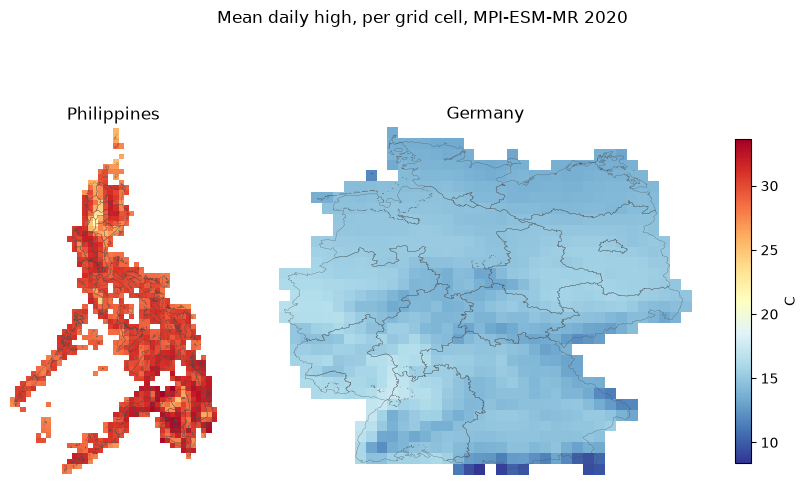

In [3]:
for iso, name in data.COUNTRIES.items():
    tasmax, _ = daily[iso]
    has_data = np.isfinite(tasmax.values[0])
    print(f"{name}: {tasmax.values.shape} (time, lat, lon), "
          f"{int(has_data.sum())} cells with data; "
          f"first longitudes {tasmax.lon[:3]}, first latitudes {tasmax.lat[:3]}")

mean_high = {iso: {"tasmax_mean": tasmax.values.mean(axis=0) - 273.15}
             for iso, (tasmax, _) in daily.items()}
grids = {iso: tasmax for iso, (tasmax, _) in daily.items()}
plots.grid_maps(grids, mean_high, "tasmax_mean", provinces, vmin=None)

## Transform

- Both metrics are calculated per cell and day, before spatial averaging.
- **Degree days:** use the midpoint of the day's high and low, then sum the degrees above 20°C for cooling or below it for heating, clipping at zero (averaging temperatures first can underestimate the result).
- **Days above 35°C:** count the days when the daily maximum temperature exceeds 35°C.

In [4]:
BASE_C = 20.0
HOT_C = 35.0


def degree_days(tasmax, tasmin, base=BASE_C):
    """Heating and cooling degree days per cell, over the year; a cell missing any day stays blank."""
    tas = (tasmax.astype("float64") + tasmin) / 2.0 - 273.15
    cdd = np.maximum(tas - base, 0.0).sum(axis=0)
    hdd = np.maximum(base - tas, 0.0).sum(axis=0)
    return hdd, cdd


def days_above(tasmax, threshold=HOT_C):
    """Days per cell whose high goes above the threshold; a cell missing any day stays blank."""
    hot = (tasmax.astype("float64") - 273.15 > threshold).sum(axis=0)
    return np.where(np.isnan(tasmax).any(axis=0), np.nan, hot)


per_cell = {}
for iso, (tasmax, tasmin) in daily.items():
    hdd, cdd = degree_days(tasmax.values, tasmin.values)
    per_cell[iso] = {"hdd": hdd, "cdd": cdd,
                     "hot_days": days_above(tasmax.values)}
    hottest = np.nanmax(tasmax.values) - 273.15
    print(f"{data.COUNTRIES[iso]}: the hottest day in any cell reaches "
          f"{hottest:.1f} C")

Philippines: the hottest day in any cell reaches 40.0 C
Germany: the hottest day in any cell reaches 38.3 C


### From the grid to cells

- `to_cells` converts each `(lat, lon)` array into a table with one row per grid cell, indexed by `cell_ix` and `cell_iy` on `BCSD_GRID`, the default grid.
- It raises an error if any coordinate is not a cell centre on that grid.
- Cells with no data are left out.

In [5]:
cells = pd.concat(
    [daily[iso][0].to_cells(per_cell[iso]) for iso in data.COUNTRIES],
    ignore_index=True,
)
print(f"{len(cells):,} grid cells")
print(cells.head().round(1).to_string(index=False))

1,665 grid cells
 cell_ix  cell_iy  hdd    cdd  hot_days
    1197      378  0.0 2705.3       0.0
    1198      378  0.0 2602.3       0.0
    1197      379  0.0 2727.5       0.0
    1198      379  0.0 2698.0       0.0
    1199      379  0.0 2596.3       0.0


## Grouping by time

With dates attached to the grid, monthly, seasonal, and annual summaries follow the same two-line pattern. Each can then be aggregated spatially

In [6]:
def mean_by(grid, labels):
    """Mean daily high per cell, in C, over the days that share each label."""
    kelvin = grid.values.astype("float64")
    return {label: kelvin[labels == label].mean(axis=0) - 273.15
            for label in np.unique(labels)}


month = {iso: tasmax.dates.astype("datetime64[M]").astype(int) % 12 + 1
         for iso, (tasmax, _) in daily.items()}
monthly = {iso: mean_by(tasmax, month[iso]) for iso, (tasmax, _) in daily.items()}

# annual is one label for every day: the mean daily high mapped above
# (that one averaged the float32 values, this one float64; they differ by up to 4e-4 C)
for iso, (tasmax, _) in daily.items():
    annual = mean_by(tasmax, np.zeros(len(tasmax.dates), dtype=int))[0]
    assert np.allclose(annual, mean_high[iso]["tasmax_mean"], rtol=0, atol=1e-3,
                       equal_nan=True)

### By month

Monthly means for the grid cells containing Manila and Berlin, plus January means for all cells in each country.

mean daily high by month, C
                           Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct   Nov   Dec
Manila (14.625, 120.875)  30.8  30.4  32.6  33.8  33.7  33.0  32.1  30.4  31.6  31.5  30.7  29.9
Berlin (52.625, 13.375)    5.3   3.4   5.2  17.6  18.6  23.5  28.2  27.6  22.2  13.5   8.8   6.8


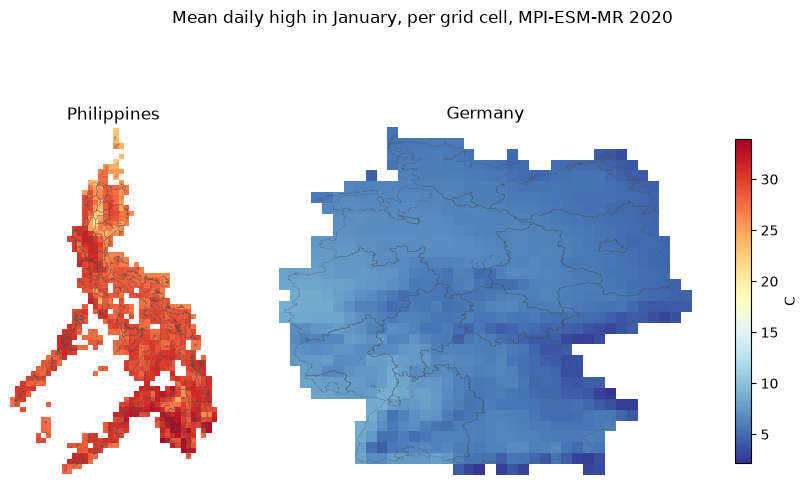

In [7]:
PLACES = {"PHL": ("Manila", 14.60, 120.98),
          "DEU": ("Berlin", 52.52, 13.40)}
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

at = {}
for iso, (place, lat, lon) in PLACES.items():
    tasmax = daily[iso][0]
    iy, ix = np.abs(tasmax.lat - lat).argmin(), np.abs(tasmax.lon - lon).argmin()
    at[iso] = (f"{place} ({tasmax.lat[iy]}, {tasmax.lon[ix]})", iy, ix)

monthly_table = pd.DataFrame({label: [monthly[iso][m][iy, ix] for m in range(1, 13)]
                      for iso, (label, iy, ix) in at.items()}, index=MONTHS)
print("mean daily high by month, C")
print(monthly_table.T.round(1).to_string())

january = {iso: {"tasmax_jan": monthly[iso][1]} for iso in daily}
plots.grid_maps(grids, january, "tasmax_jan", provinces, vmin=None)

### By season

Seasonal means follow the same pattern. Here, DJF combines January, February, and December of the same year, since the file covers only one year.

mean daily high by season, C
Manila (14.625, 120.875)       JJA  31.8   DJF  30.4
Berlin (52.625, 13.375)        JJA  26.4   DJF   5.3


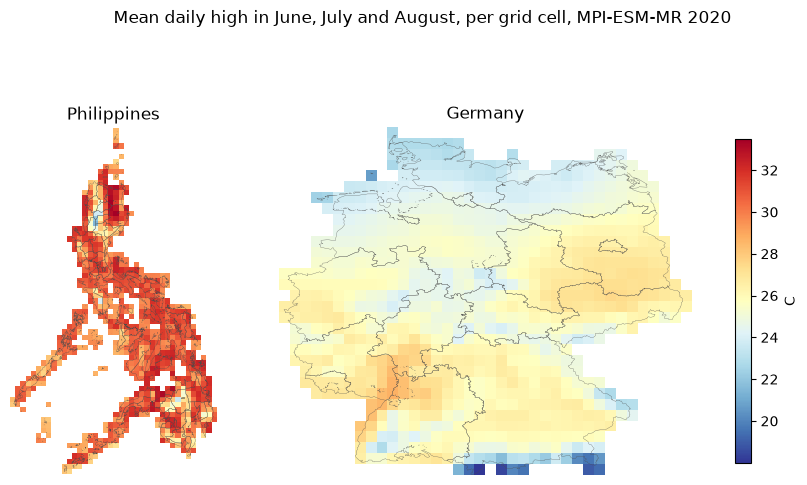

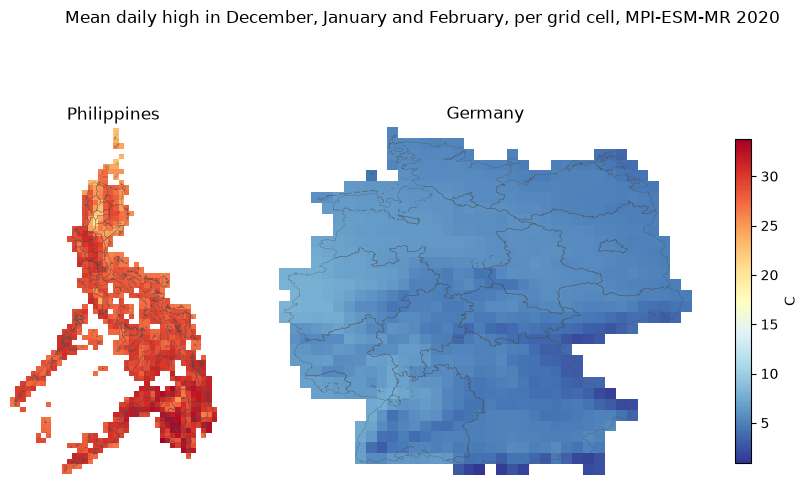

In [8]:
SEASONS = {6: "JJA", 7: "JJA", 8: "JJA", 12: "DJF", 1: "DJF", 2: "DJF"}

seasonal = {}
for iso, (tasmax, _) in daily.items():
    season = np.array([SEASONS.get(m, "other") for m in month[iso]])
    seasonal[iso] = mean_by(tasmax, season)

print("mean daily high by season, C")
for iso, (label, iy, ix) in at.items():
    print(f"{label:30s} JJA {seasonal[iso]['JJA'][iy, ix]:5.1f}"
          f"   DJF {seasonal[iso]['DJF'][iy, ix]:5.1f}")

by_season = {iso: {"tasmax_jja": s["JJA"], "tasmax_djf": s["DJF"]}
             for iso, s in seasonal.items()}
for col in ("tasmax_jja", "tasmax_djf"):
    plots.grid_maps(grids, by_season, col, provinces, vmin=None)

## Aggregate

### Provinces

- The weights map the 0.25° grid to GADM 2.0 ADM1 provinces using population and area shares.
- They were generated from the GADM 2.0 ADM1 boundaries and the GPW v4 rev 10 population raster, adjusted to UN World Population Prospects. `prepare_data.py` subsets them to the Philippines and Germany on Midway3.

`apply_weights` raises an error for cells it cannot account for. Here, two settings allow cells to be skipped, with a message reporting each:

- `on_zero_weight="skip"`: skips cells that overlap a province but have zero population weight.
- `on_unmatched="skip"`: skips cells with data but no matching weights. All cells match the province weights, so none are skipped here. The Berkeley segment weights are missing 13 cells, which are skipped in the impact region aggregation and shown as “generated weights only” in the final comparison.

`on_absent_from_data="error"` keeps the run from continuing if a cell listed in the weights has no data.

`apply_weights` accepts one value column and treats all other columns as dimensions. The three fields are therefore stacked into one value column, identified by a `field` column, and returned in the same format.

In [9]:
KEYS = ["ISO", "ID_1"]
FIELDS = ["hdd", "cdd", "hot_days"]

province_weights = cilreg.WeightsArtifact.load(data.WEIGHTS)
policies = cilreg.SourceUnitPolicies(on_zero_weight="skip", on_unmatched="skip")


def aggregate(weights, weight):
    """Average every field over each region, weighted by population or area."""
    long = cells.melt(id_vars=["cell_ix", "cell_iy"], var_name="field")
    result = cilreg.apply_weights(
        weights,
        long,
        kind="intensive",    # an average, not a total
        weight=weight,       # "pop" or "area"
        data_version=BCSD_GRID,  # the grid the cells are on; checked against the weights
        policies=policies,
    )
    ids = list(weights.schema.id_fields)
    return (result.frame.pivot(index=ids, columns="field", values="value")
            .reset_index().rename_axis(columns=None))


by_pop = aggregate(province_weights, "pop")
by_area = aggregate(province_weights, "area")
print(by_pop.head().round(1).to_string(index=False))

source coverage: 4 zero_weight source units (first 4: [[1193, 395], [1194, 391], [1202, 404], [1206, 385]]); recorded in the manifest and skipped


ISO  ID_1   cdd    hdd  hot_days
DEU     1 142.4 3426.4       0.5
DEU     2  93.7 3742.3       0.0
DEU     3 149.0 3459.4       0.0
DEU     4 150.2 3467.9       0.0
DEU     5  90.2 3447.0       0.0


- Country-level results weight each province by its total population or area, stored as `pop_raw` and `area_raw` in the weights file.
- The last two columns divide heating and cooling degree days by 365: the average daily shortfall below 20°C and excess above it, based on the midpoint of the day's high and low (days on the other side count as zero).

In [10]:
def national(units, weight):
    mass = (province_weights.frame.groupby(KEYS)[f"{weight}_raw"].sum()
            .rename("mass").reset_index())
    m = units.merge(mass, on=KEYS, validate="one_to_one")
    totals = m[FIELDS].multiply(m["mass"], axis=0).groupby(m["ISO"]).sum()
    return totals.divide(m.groupby("ISO")["mass"].sum(), axis=0)


print(f"{'':32s}{'heating':>9s}{'cooling':>9s}{'>35 C':>7s}"
      f"{'C below/day':>13s}{'C above/day':>13s}")
for label, units, weight in (("population weighted", by_pop, "pop"),
                             ("area weighted", by_area, "area")):
    n = national(units, weight)
    for iso, name in data.COUNTRIES.items():
        h, c, hot = n.loc[iso, ["hdd", "cdd", "hot_days"]]
        print(f"{name + ', ' + label:32s}{h:9,.0f}{c:9,.0f}{hot:7.1f}"
              f"{h / 365:13.1f}{c / 365:13.1f}")

                                  heating  cooling  >35 C  C below/day  C above/day
Philippines, population weighted        4    2,411    2.2          0.0          6.6
Germany, population weighted        3,460      126    0.3          9.5          0.3
Philippines, area weighted             12    2,104    1.9          0.0          5.8
Germany, area weighted              3,588      109    0.2          9.8          0.3


### The same weights, from a CSV

`data/adm1_weights.csv` holds the same province weights as a plain
table. These are its first rows:

In [11]:
csv = pd.read_csv(data.WEIGHTS_CSV)
print(f"{len(csv):,} rows")
print(csv.head().to_string(index=False))

2,356 rows
ISO  ID_1  pix_cent_x  pix_cent_y    popwt   areawt
DEU     1       7.625      47.625 0.013959 0.008623
DEU     1       7.625      47.875 0.011640 0.010449
DEU     1       7.625      48.125 0.007992 0.008401
DEU     1       7.625      48.375 0.000669 0.001204
DEU     1       7.875      47.625 0.009035 0.010393


`from_table` needs three kinds of column:

- the region id, here `ISO` and `ID_1`, passed as `id_fields`;
- one column per weight, here `popwt` and `areawt`, named in
  `weights`. In each one the shares add up to one within a region;
- the centre of each grid cell, here `pix_cent_x` and `pix_cent_y`.
  `lon` and `lat`, or `cell_lon` and `cell_lat`, also work.

In [12]:
from_csv = cilreg.WeightsArtifact.from_table(
    data.WEIGHTS_CSV,
    id_fields=["ISO", "ID_1"],
    weights={"pop": "popwt", "area": "areawt"},
    source=BCSD_GRID,
)
for weight, a in (("pop", by_pop), ("area", by_area)):
    # from_table reads ids from a CSV as strings; compare them as numbers
    b = aggregate(from_csv, weight).astype({"ID_1": "int64"})
    both = a.merge(b, on=KEYS, suffixes=("", "_csv"), validate="one_to_one")
    diff = max(float((both[c] - both[f"{c}_csv"]).abs().max()) for c in FIELDS)
    print(f"{weight} weights: the weights file and the CSV agree on "
          f"{len(both)} provinces, largest difference {diff:.1e}")

source coverage: 4 zero_weight source units (first 4: [[1193, 395], [1194, 391], [1202, 404], [1206, 385]]); recorded in the manifest and skipped


pop weights: the weights file and the CSV agree on 98 provinces, largest difference 0.0e+00
area weights: the weights file and the CSV agree on 98 provinces, largest difference 0.0e+00


### Impact regions

The impact region weights use the same three types of columns as the CSV:

- **Region ID:** `hierid`.
- **Population and area shares:** `popwt` and `areawt`.
- **Cell centres:** `pix_cent_x` and `pix_cent_y`.

`from_table` reads these columns directly.

- **Source:** weights used for aggregation on the Berkeley servers, documented in [climate_transform_specs](https://gitlab.com/ClimateImpactLab/Climate/climate_transform_specs).
- **Backup copy:** `/project/cil/home_dirs/jonahmgilbert/archive/data/agglomerated-world-new_BCSD_grid_segment_weights_area_pop.csv`.


In [13]:
table = pd.read_parquet(data.IR_TABLE)
print(f"{len(table):,} rows, {table['hierid'].nunique()} impact regions")
print(table.head().to_string(index=False))

ir_weights = cilreg.WeightsArtifact.from_table(
    data.IR_TABLE,
    id_fields=["hierid"],
    weights={"pop": "popwt", "area": "areawt"},
    source=BCSD_GRID,
)
by_ir = aggregate(ir_weights, "pop")
blank = sorted(set(impact_regions["hierid"]) - set(by_ir["hierid"]))
if blank:
    print(f"regions with no population share, drawn in grey: {blank}")
for iso, name in data.COUNTRIES.items():
    s = by_ir[by_ir["hierid"].str[:3] == iso]
    print(f"{name}: {len(s)} impact regions, {(s['hot_days'] > 0).sum()} "
          f"with at least one day above 35 C")

source coverage: 13 unmatched source units (first 10: [[1193, 397], [1200, 418], [1201, 381], [1201, 402], [1201, 407], [1205, 383], [1205, 436], [1207, 417], [1214, 403], [1217, 401]]); recorded in the manifest and skipped


source coverage: 53 zero_weight source units (first 10: [[747, 573], [751, 576], [752, 575], [753, 577], [753, 580], [754, 576], [759, 549], [772, 551], [772, 552], [775, 577]]); recorded in the manifest and skipped


3,437 rows, 400 impact regions
ISO     area   color   gadmid           hierid  pix_cent_x  pix_cent_y    pop  areatotal  poptotal   areawt   popwt      shpid
PHL 0.000447 19710.0 126458.0 PHL.25.458.11236     123.875      10.375 9477.0   0.000458    9477.0 0.976504 1.00000 GCPREGIONS
PHL 0.000011 19710.0 126458.0 PHL.25.458.11236     124.125      10.375    0.0   0.000458    9477.0 0.023496 0.00000 GCPREGIONS
PHL 0.001107 19711.0 139487.0 PHL.28.521.12710     125.375       5.625  732.0   0.001211     762.0 0.914583 0.96063 GCPREGIONS
PHL 0.000094 19711.0 139487.0 PHL.28.521.12710     125.375       5.875   30.0   0.001211     762.0 0.077598 0.03937 GCPREGIONS
PHL 0.000009 19711.0 139487.0 PHL.28.521.12710     125.625       5.625    0.0   0.001211     762.0 0.007819 0.00000 GCPREGIONS
Philippines: 200 impact regions, 87 with at least one day above 35 C
Germany: 200 impact regions, 68 with at least one day above 35 C


## Map

- Results are shown first for individual grid cells, without weighting, then for provinces and impact regions, using population weights.
- Each map uses the same colour scale for both countries.

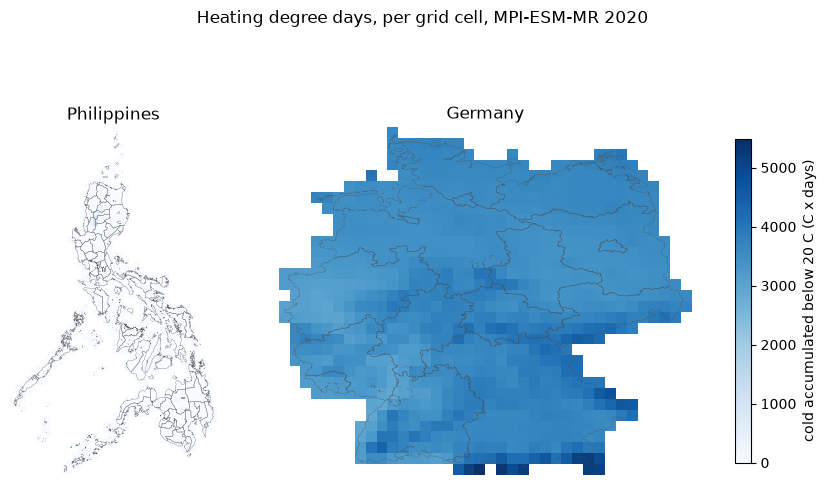

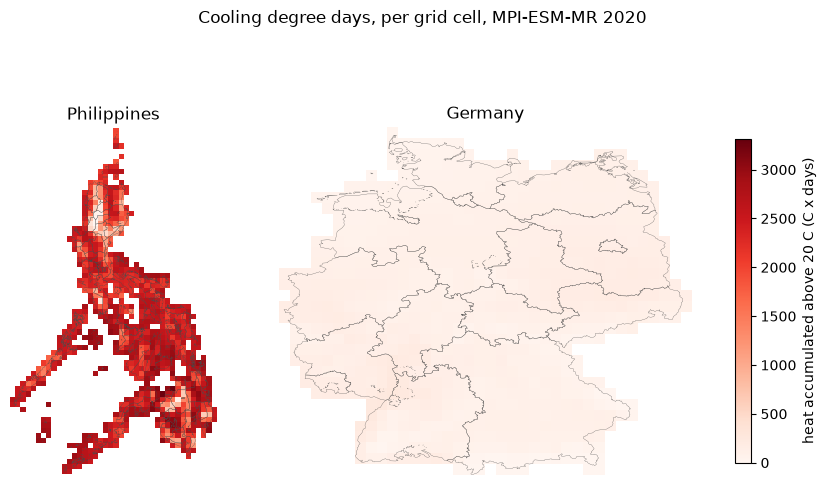

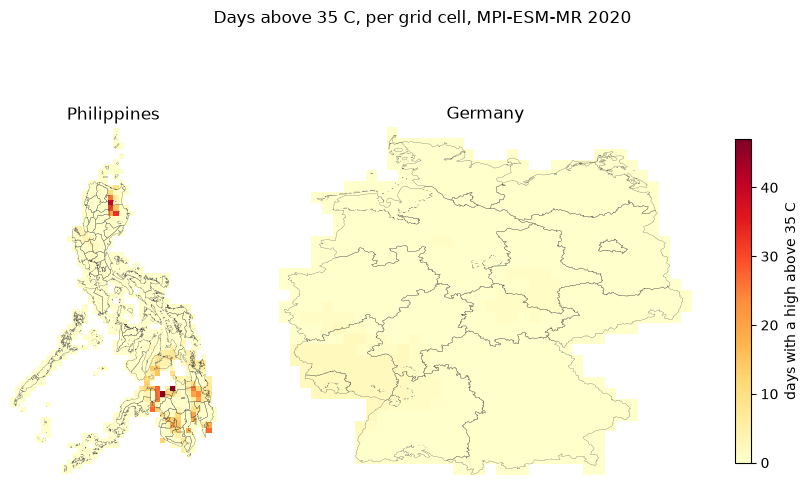

In [14]:
for col in FIELDS:
    plots.grid_maps(grids, per_cell, col, provinces)

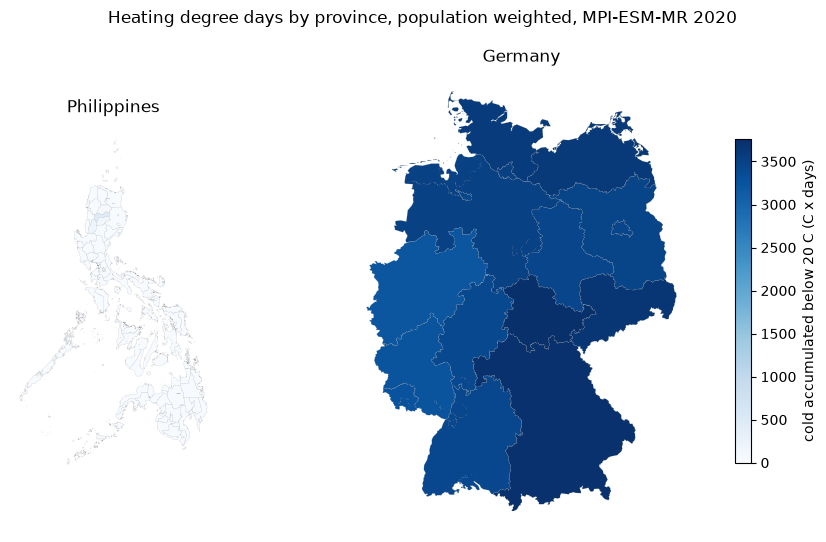

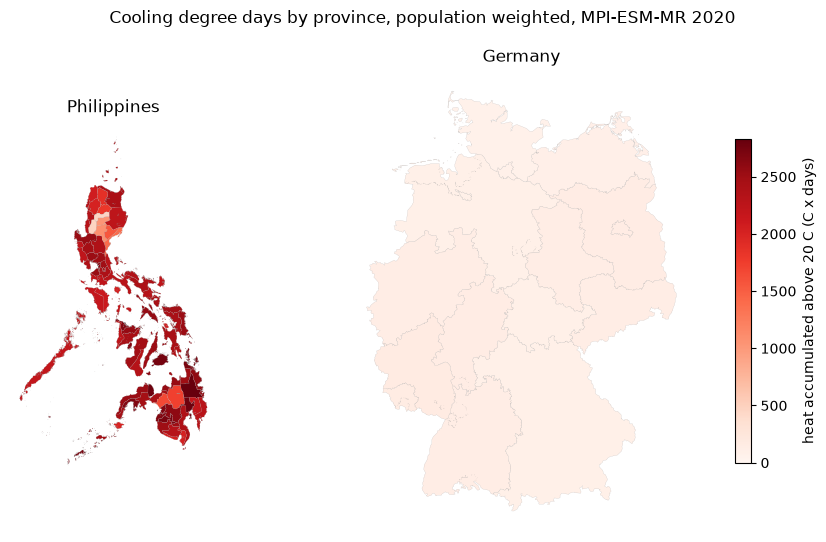

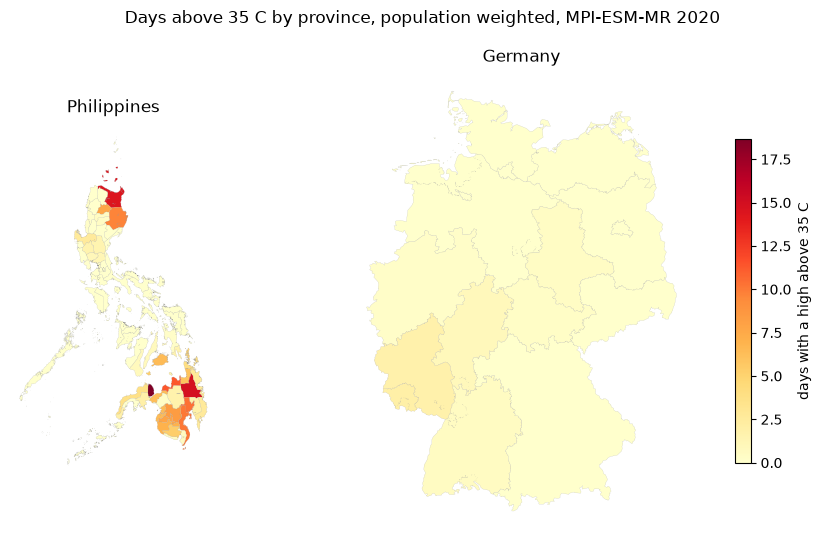

In [15]:
province_map = provinces.merge(by_pop, on=KEYS, how="left")
for col in FIELDS:
    plots.region_maps(province_map, col, "province")

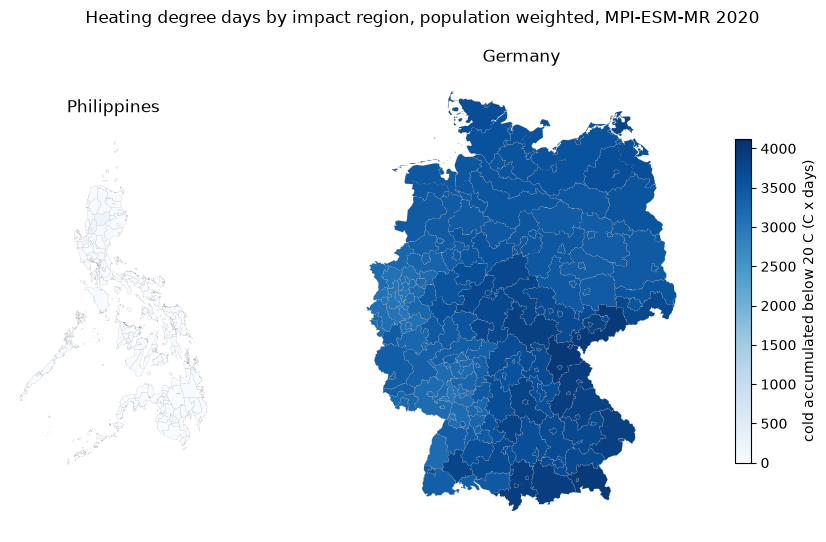

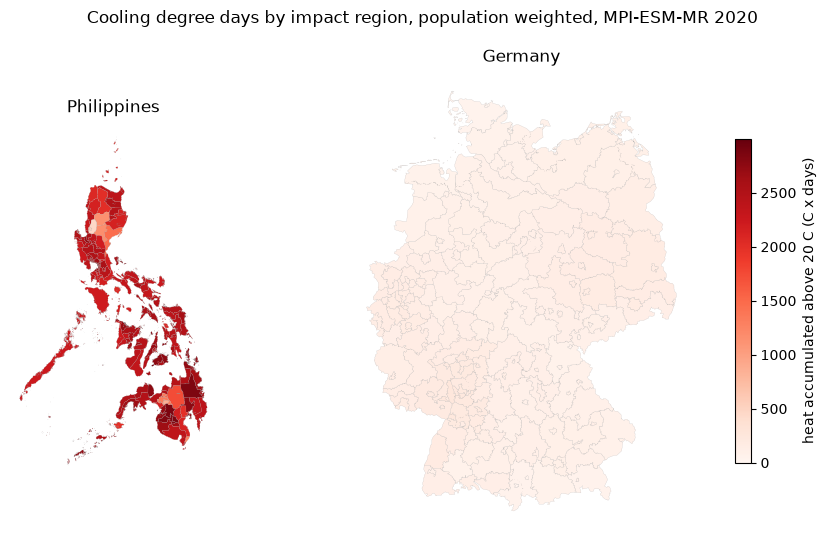

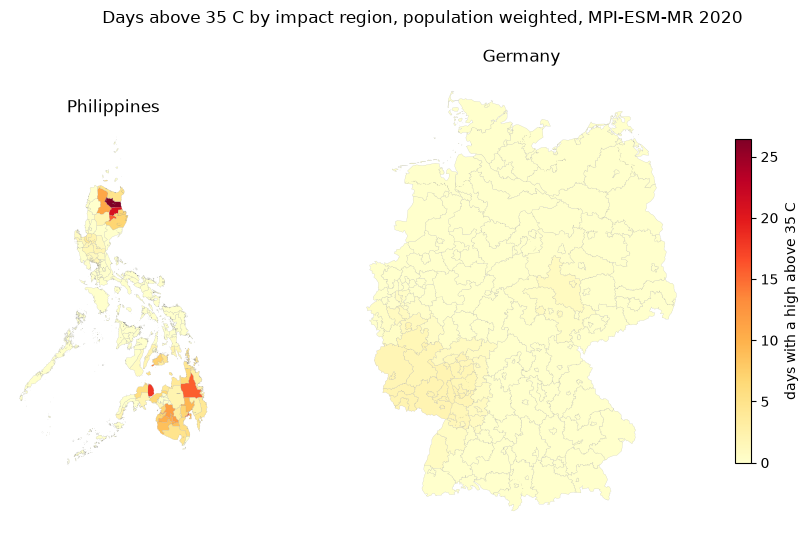

In [16]:
ir_map = impact_regions.merge(by_ir, on="hierid", how="left")
for col in FIELDS:
    plots.region_maps(ir_map, col, "impact region")

## Two sets of impact region weights

The same degree days are aggregated using two sets of weights:

- **Berkeley segment weights.**
- **Generated weights:** created by `prepare_data.py` on Midway3 using `grid025_to_ir_phl_deu.toml` and stored in `data/weights/grid025_ir_phl_deu_per_destination/`.

Differences below are generated minus segment results, in °C·days.

In [17]:
generated = cilreg.WeightsArtifact.load(data.IR_WEIGHTS)
by_generated = aggregate(generated, "pop")

key = ["cell_ix", "cell_iy"]
cell_sets = ir_weights.frame[key].drop_duplicates().merge(
    generated.frame[key].drop_duplicates(), how="outer", indicator=True)
print("grid cells:")
print(cell_sets["_merge"].cat.rename_categories(
    {"both": "in both", "left_only": "segment weights only",
     "right_only": "generated weights only"}).value_counts().to_string(), "\n")

diff = by_ir.merge(by_generated, on="hierid", suffixes=("_segment", "_generated"))
for c in ("hdd", "cdd"):
    diff[f"{c}_diff"] = diff[f"{c}_generated"] - diff[f"{c}_segment"]
diff["ISO"] = diff["hierid"].str[:3]
print(f"{len(diff)} impact regions have a population weighted value from both")
print(diff.groupby("ISO")[["hdd_diff", "cdd_diff"]]
      .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T.round(1).to_string())

source coverage: 4 zero_weight source units (first 4: [[1193, 395], [1194, 391], [1202, 404], [1206, 385]]); recorded in the manifest and skipped


grid cells:
_merge
in both                   1652
generated weights only      13
segment weights only         0 

400 impact regions have a population weighted value from both
ISO               DEU    PHL
hdd_diff count  200.0  200.0
         mean     4.8    1.4
         std     20.4   13.2
         min    -94.2   -5.6
         5%     -11.7   -0.2
         25%     -1.2    0.0
         50%      1.1    0.0
         75%      6.8    0.0
         95%     36.0    0.5
         max    146.4  165.3
cdd_diff count  200.0  200.0
         mean    -0.7   -9.6
         std      3.2   55.9
         min    -21.1 -352.1
         5%      -6.7  -97.8
         25%     -1.3  -20.8
         50%     -0.1    0.0
         75%      0.3    1.9
         95%      2.2   36.8
         max     12.8  354.9


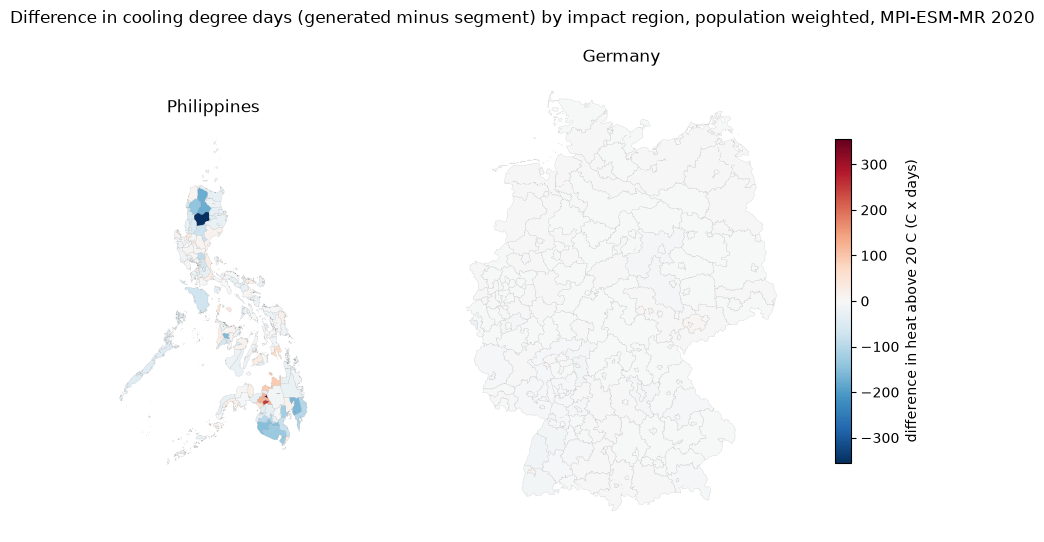

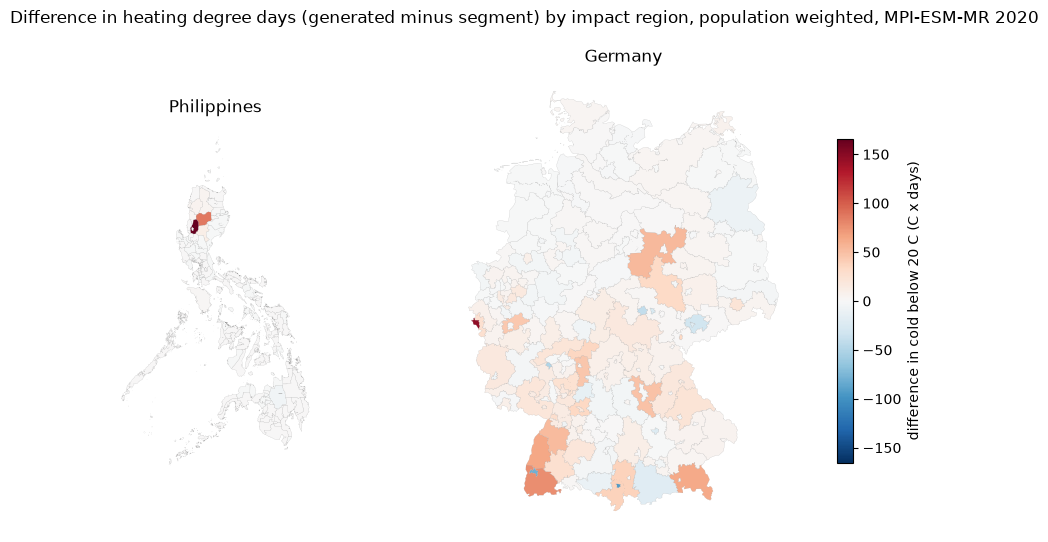

In [18]:
diff_map = impact_regions.merge(diff[["hierid", "hdd_diff", "cdd_diff"]],
                                on="hierid", how="left")
for col in ("cdd_diff", "hdd_diff"):
    plots.region_maps(diff_map, col, "impact region", symmetric=True)